# Long/Short Fallen Angel Reversion

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from   matplotlib.ticker import FuncFormatter

In [2]:
note_path = os.getcwd()
repo_path = os.path.abspath(os.path.join(note_path, ".."))
data_path = os.path.join(repo_path, "data")
sig_path  = os.path.join(data_path, "Signal")

In [3]:
fi_ticker_map = {
    'AGG'     : "IG", 
    'HYG'     : "HY", 
    'JNK'     : "HY", 
    'LBUSTRUU': "IG", 
    'LF98TRUU': "HY", 
    'LQD'     : "IG"}

renamer = {
    "lagged" : "Lagged",
    "perfect": "Contemporaneous",
    "no"     : "No",
    "etf"    : "ETF",
    "index"  : "TRUU Index",
    "HY"     : "High Yield",
    "IG"     : "Investment Grade"}

# Mean Reversion Approach

In [4]:
rtn_path = os.path.join(sig_path, "MeanReversionRtn.parquet")
df_prep  = (pd.read_parquet(
    path = rtn_path, engine = "pyarrow").
    loc[lambda x: x.fi_ticker != "SJNK"].
    assign(
        signal_rtn = lambda x: -np.sign(x.lag_signal) * x.spread_rtn,
        name       = lambda x: x.asset + " " + x.fa_ticker + " " + x.fi_ticker))

In [5]:
def _vol_rtn(df: pd.DataFrame, shift: int) -> pd.DataFrame:

    df_out = (df.sort_values(
        "date").
        assign(vol_rtn = lambda x: x.signal_rtn * (0.1 / (x.signal_rtn.ewm(span = 100, adjust = False).std().shift(shift) * np.sqrt(252)))))

    return df_out

df_none = (df_prep.loc[
    lambda x: x.hedge == "no"].
    assign(vol_rtn = lambda x: x.signal_rtn))

df_lag = (df_prep.loc[
    lambda x: x.hedge == "lagged"].
    groupby("name").
    apply(_vol_rtn, 1).
    reset_index().
    drop(columns = ["level_1"]))

df_perf = (df_prep.loc[
    lambda x: x.hedge == "perfect"].
    groupby("name").
    apply(_vol_rtn, 0).
    reset_index().
    drop(columns = ["level_1"]))

df_vol_rtn = (pd.concat(
    [df_none, df_lag, df_perf]).
    assign(
        fi_type   = lambda x: x.fi_ticker.map(fi_ticker_map),
        group_var = lambda x: x.hedge + " " + x.asset + " " + x.fi_type,
        name      = lambda x: x.fa_ticker + "-" + x.fi_ticker))

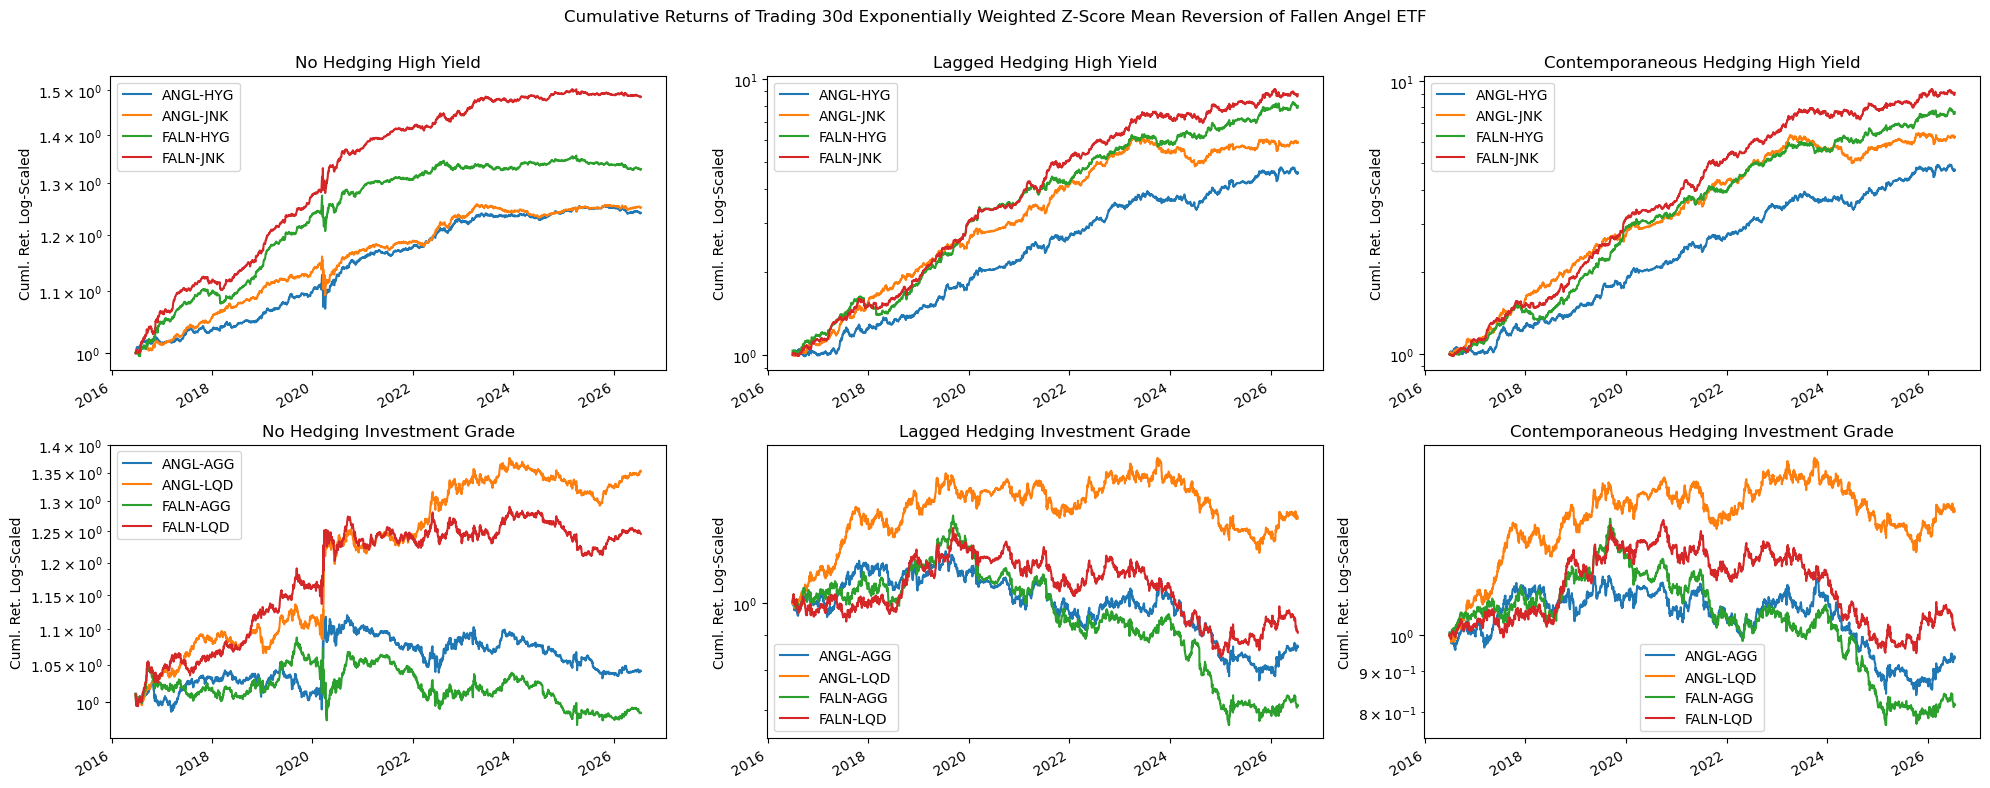

In [6]:
group_vars = df_vol_rtn.sort_values("fi_type").group_var.drop_duplicates().to_list()
fig, axes  = plt.subplots(ncols = 3, nrows = 2, figsize = (20,8))

for group_var, ax in zip(group_vars, axes.flatten()):

    hedge, asset_class, fi_type = group_var.split(" ")
    
    (df_vol_rtn.loc[
        lambda x: x.group_var == group_var].
        rename(columns = {"name": ""}).
        pivot(index = "date", columns = "", values = "vol_rtn").
        dropna().
        apply(lambda x: np.cumprod(1 + x)).
        plot(
            ax     = ax,
            logy   = True,
            xlabel = "",
            ylabel = "Cuml. Ret. Log-Scaled",
            title  = (
                renamer[hedge] + " Hedging " + 
                renamer[fi_type])))

fig.suptitle("Cumulative Returns of Trading 30d Exponentially Weighted Z-Score Mean Reversion of Fallen Angel ETF\n")
plt.tight_layout()

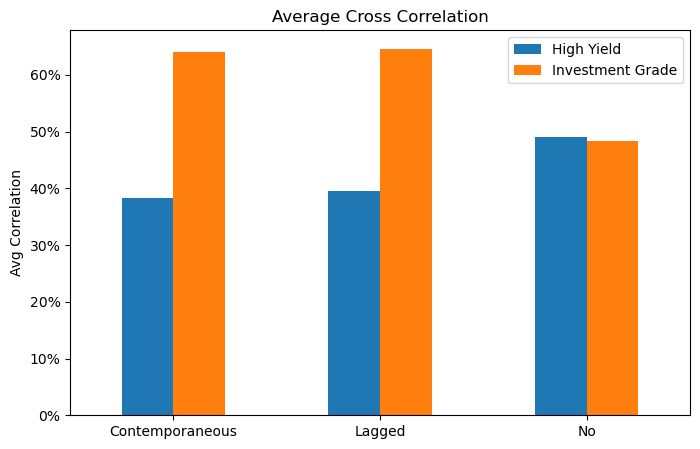

In [7]:
def _get_avg_corr(df: pd.DataFrame) -> pd.DataFrame: 

    df_corr = (df.pivot(
        index = "date", columns = "name", values = "vol_rtn").
        corr())

    mask = np.triu(np.ones(df_corr.shape, dtype=bool), k=1)
    return df_corr.where(mask).stack().mean()

_, axes = plt.subplots(figsize = (8,5))

(df_vol_rtn.groupby(
    "group_var").
    apply(_get_avg_corr).
    to_frame(name = "avg_corr").
    reset_index().
    assign(
        hedging = lambda x: x.group_var.str.split(" ").str[0].map(renamer),
        fi_type = lambda x: x.group_var.str.split(" ").str[-1].map(renamer)).
    rename(columns = {"fi_type": ""}).
    pivot(index = "hedging", columns = "", values = "avg_corr").
    plot(
        kind   = "bar", 
        rot    = 0,
        xlabel = "", 
        ylabel = "Avg Correlation",
        ax     = axes,
        title  = "Average Cross Correlation"))

axes.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))

In [8]:
df_sharpe = (df_vol_rtn[
    ["name", "hedge", "fi_type", "vol_rtn"]].
    groupby(["name", "hedge", "fi_type"]).
    agg(lambda x: x.mean() / x.std() * np.sqrt(252)).
    reset_index())

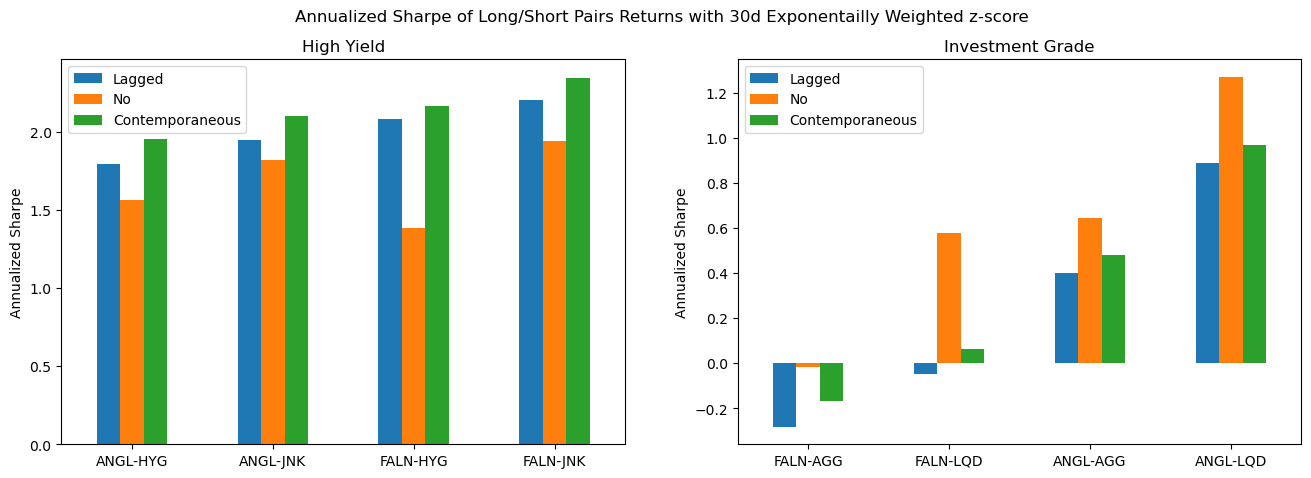

In [9]:
group_vars = df_sharpe.fi_type.drop_duplicates().sort_values().to_list()
fig, axes  = plt.subplots(ncols = len(group_vars), figsize = (16,5))

for group_var, ax in zip(group_vars, axes.flatten()): 

    (df_sharpe.loc[
        lambda x: x.fi_type == group_var].
        rename(columns = {"hedge": ""}).
        pivot(index = "name", columns = "", values = "vol_rtn").
        sort_values("perfect").
        rename(columns = renamer).
        plot(
            ax     = ax,
            kind   = "bar",
            rot    = 0,
            xlabel = "",
            ylabel = "Annualized Sharpe",
            title  = renamer[group_var]))

fig.suptitle("Annualized Sharpe of Long/Short Pairs Returns with 30d Exponentailly Weighted z-score\n")
plt.show()

In [10]:
df_port = (df_vol_rtn[
    ["date", "fi_type", "hedge", "vol_rtn"]].
    groupby(["date", "fi_type", "hedge"]).
    agg("mean").
    reset_index().
    dropna())

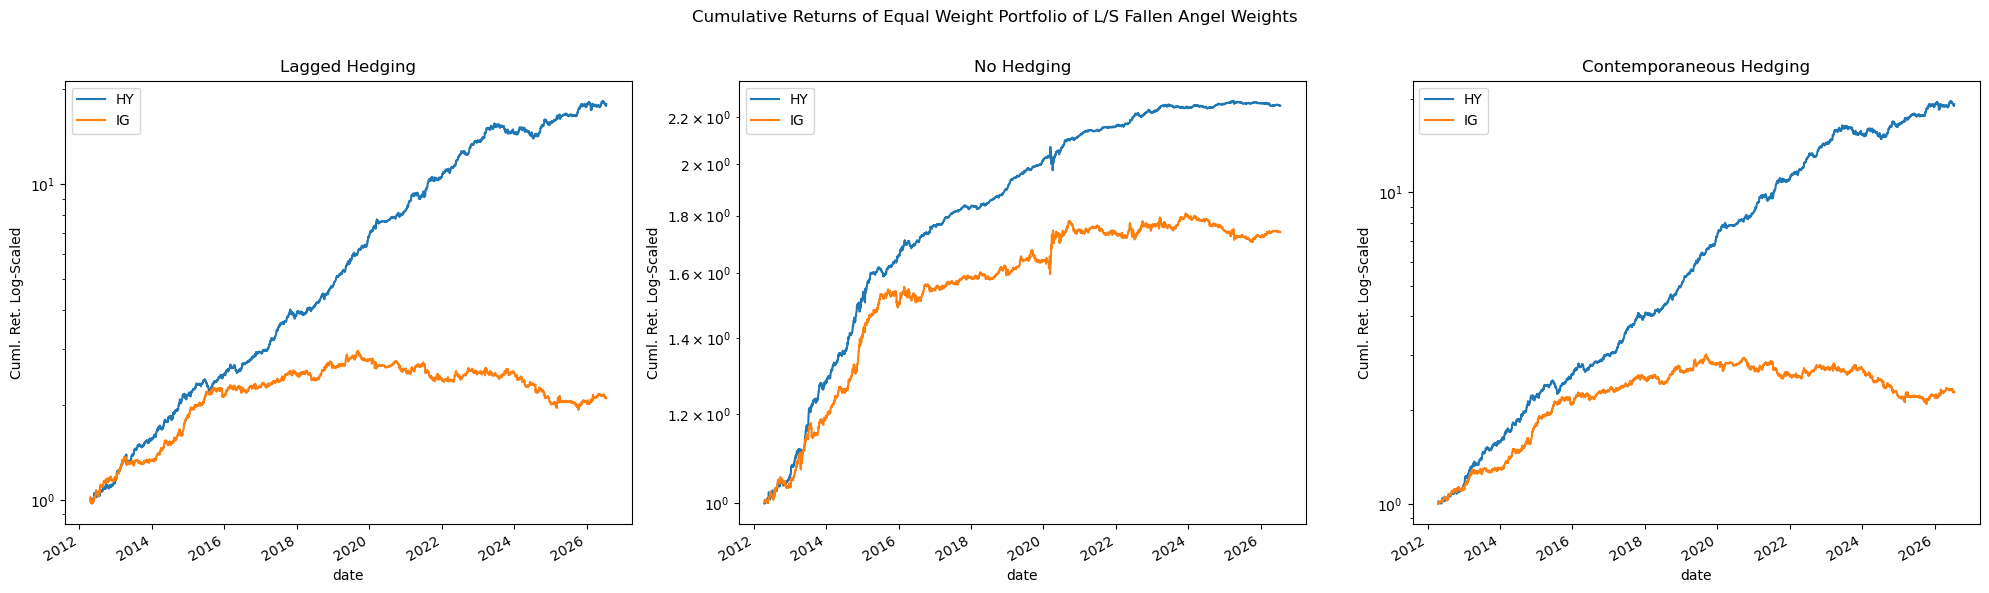

In [11]:
hedges    = df_port.hedge.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(hedges), figsize = (20,6)) 

for hedge, ax in zip(hedges, axes.flatten()):

    (df_port.loc[
        lambda x: x.hedge == hedge].
        rename(columns = {"fi_type": ""}).
        pivot(index = "date", columns = "", values = "vol_rtn").
        apply(lambda x: np.cumprod(1 + x)).
        plot(
            ax     = ax,
            logy   = True,
            ylabel = "Cuml. Ret. Log-Scaled",
            title  = renamer[hedge] + " Hedging"))

fig.suptitle("Cumulative Returns of Equal Weight Portfolio of L/S Fallen Angel Weights\n")
plt.tight_layout()

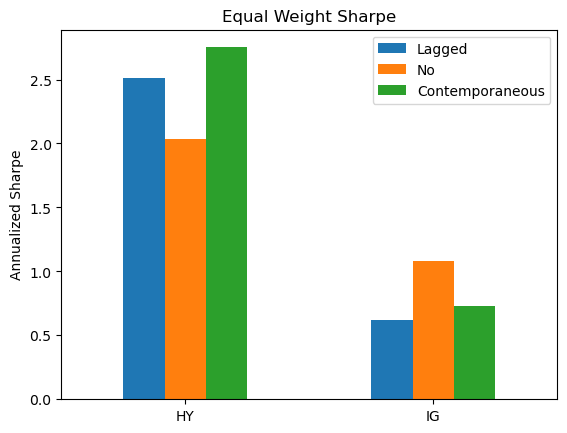

In [12]:
(df_port.drop(
    columns = ["date"]).
    groupby(["fi_type", "hedge"]).
    agg(lambda x: x.mean() / x.std() * np.sqrt(252)).
    reset_index().
    rename(columns = {"hedge": ""}).
    pivot(index = "fi_type", columns = "", values = "vol_rtn").
    rename(columns = renamer).
    plot(
        kind   = "bar",
        rot    = 0,
        xlabel = "",
        ylabel = "Annualized Sharpe",
        title  = "Equal Weight Sharpe"))

plt.show()